In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency
import math
from scipy import stats
%matplotlib inline

In [2]:
# Loading dataset 
df = pd.read_csv(r"C:\Users\Tanguy\Documents\IRONHACK\Week5\Day1\amz_uk_price_prediction_dataset.csv")
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [3]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.

Crosstab Analysis:

Create a crosstab between the product category and the isBestSeller status.

Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

Statistical Tests:

Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
Compute Cramér's V to understand the strength of association between best-seller status and category.
Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [4]:
# Generating a crosstab between the product category and the isBestSeller status
crosstab= pd.crosstab(df['category'], df['isBestSeller'])

crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [5]:
# Add missing columns if they don't exist (in case there's no 0 or no 1 for a category)
if 0 not in crosstab.columns:
    crosstab[0] = 0
if 1 not in crosstab.columns:
    crosstab[1] = 0

In [6]:
# Calculate the proportion of best-sellers in each category
crosstab_prop = crosstab.div(crosstab.sum(axis=1), axis=0)
crosstab_prop

isBestSeller,False,True,0
category,,,
3D Printers,0.995968,0.004032,0.0
3D Printing & Scanning,0.999508,0.000492,0.0
Abrasive & Finishing Products,0.980000,0.020000,0.0
Action Cameras,0.999411,0.000589,0.0
Adapters,0.988189,0.011811,0.0
...,...,...,...
Wind Instruments,0.972000,0.028000,0.0
Window Treatments,0.979079,0.020921,0.0
Women,0.988015,0.011985,0.0


In [7]:
# Sort categories based on the proportion of best-sellers
crosstab_sorted = crosstab_prop.sort_values(by=1, ascending=False)
crosstab_sorted

isBestSeller,False,True,0
category,,,
Grocery,0.941865,0.058135,0.0
Smart Home Security & Lighting,0.942308,0.057692,0.0
Health & Personal Care,0.942314,0.057686,0.0
Mobile Phone Accessories,0.957529,0.042471,0.0
Power & Hand Tools,0.964661,0.035339,0.0
...,...,...,...
"CD, Disc & Tape Players",1.000000,0.000000,0.0
General Music-Making Accessories,1.000000,0.000000,0.0
Snowboard Boots,1.000000,0.000000,0.0


In [8]:
print("Crosstab of Categories and Best-Seller Status:\n", crosstab)
print("\nProportions:\n", crosstab_sorted)

Crosstab of Categories and Best-Seller Status:
 isBestSeller                    False  True  0
category                                      
3D Printers                       247     1  0
3D Printing & Scanning           4065     2  0
Abrasive & Finishing Products     245     5  0
Action Cameras                   1696     1  0
Adapters                          251     3  0
...                               ...   ... ..
Wind Instruments                  243     7  0
Window Treatments                 234     5  0
Women                           17559   213  0
Women's Sports & Outdoor Shoes   1939    20  0
eBook Readers & Accessories       246     0  0

[296 rows x 3 columns]

Proportions:
 isBestSeller                         False      True    0
category                                                 
Grocery                           0.941865  0.058135  0.0
Smart Home Security & Lighting    0.942308  0.057692  0.0
Health & Personal Care            0.942314  0.057686  0.0
Mobile Phone

In [9]:
# 2. Chi-square Test
# Adding a small value to cells with zero counts to avoid chi-square errors
crosstab_corrected = crosstab + 0.5

# Chi-square Test
chi2, p, dof, ex = chi2_contingency(crosstab_corrected)
print(f"\nChi-square test: chi2 = {chi2}, p-value = {p}, degrees of freedom = {dof}")


Chi-square test: chi2 = 37922.59144381576, p-value = 0.0, degrees of freedom = 590


In [10]:
# Cramér's V
n = crosstab.sum().sum()  # total sample size
cramers_v = math.sqrt(chi2 / (n * (min(crosstab.shape) - 1)))
print(f"\nCramér's V: {cramers_v}")


Cramér's V: 0.08808752658079365


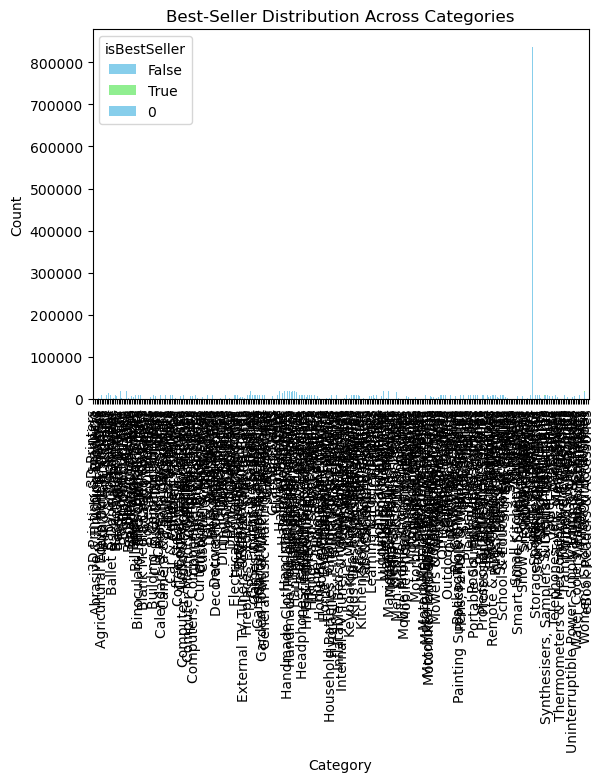

In [13]:
# 3. Visualizations

# Stacked Bar Chart for the relationship between categories and best-seller status
crosstab.plot(kind='bar', stacked=True, color=['skyblue', 'lightgreen'])
plt.title('Best-Seller Distribution Across Categories')
plt.xlabel('Category')
plt.ylabel('Count')
plt.show()

<Figure size 1000x600 with 0 Axes>

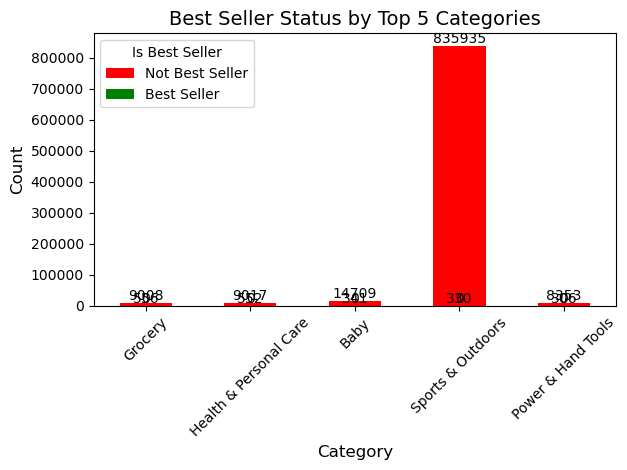

In [16]:
# Visualization

# Step 2: Sort the crosstab by the total best-sellers
crosstab = crosstab.sort_values(by=True, ascending=False)

# Step 3: Limit to the top 5 categories
top_categories = crosstab.head(5)

# Plot stacked bar chart
plt.figure(figsize=(10, 6))  # Increase figure size
top_categories.plot(kind='bar', stacked=True, color=['red', 'green'])
plt.title('Best Seller Status by Top 5 Categories', fontsize=14)
plt.xlabel('Category', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=45)  # Rotate x-ticks
plt.legend(title='Is Best Seller', labels=['Not Best Seller', 'Best Seller'], fontsize=10)
plt.tight_layout()  # Adjust layout

# Add value labels
for i in range(len(top_categories)):
    for j in range(len(top_categories.columns)):
        count = top_categories.values[i][j]
        plt.text(i, count + 0.1, str(count), ha='center', va='bottom', fontsize=10)

plt.show()

Part 2: Exploring Product Prices and Ratings Across Categories and Brands
Objective: Investigate how different product categories influence product prices.

Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

Violin Plots:

Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
Which product category tends to have the highest median price? Don't filter here by top categories.
Bar Charts:

Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
Which product category commands the highest average price? Don't filter here by top categories.
Box Plots:

Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [18]:
# Step 1: Remove Outliers in Product Prices using IQR
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
IQR

36.0

In [19]:
# Calculate the limits for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
lower_bound ,upper_bound

(-44.01, 99.99000000000001)

In [25]:
# Filter out the outliers
df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]
df_no_outliers

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


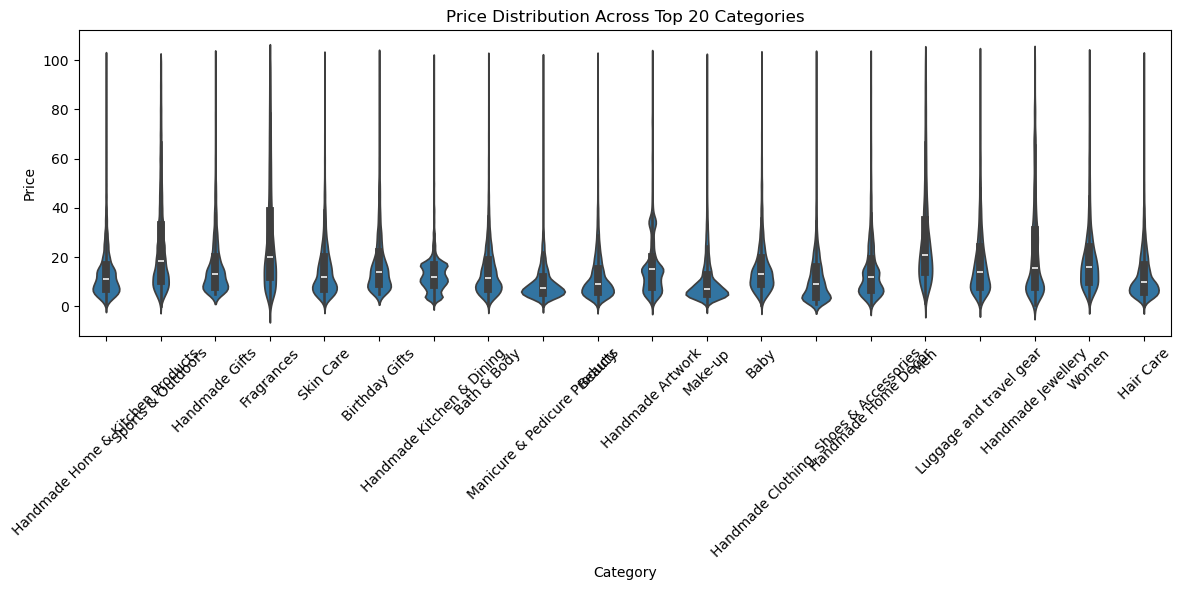

In [27]:
# Step 2: Violin Plots
# Get top 20 categories based on count
top_categories = df_no_outliers['category'].value_counts().nlargest(20).index

plt.figure(figsize=(12, 6))
sns.violinplot(x='category', y='price', data=df_no_outliers[df_no_outliers['category'].isin(top_categories)])
plt.title('Price Distribution Across Top 20 Categories')
plt.xticks(rotation=45)
plt.ylabel('Price')
plt.xlabel('Category')
plt.tight_layout()
plt.show()

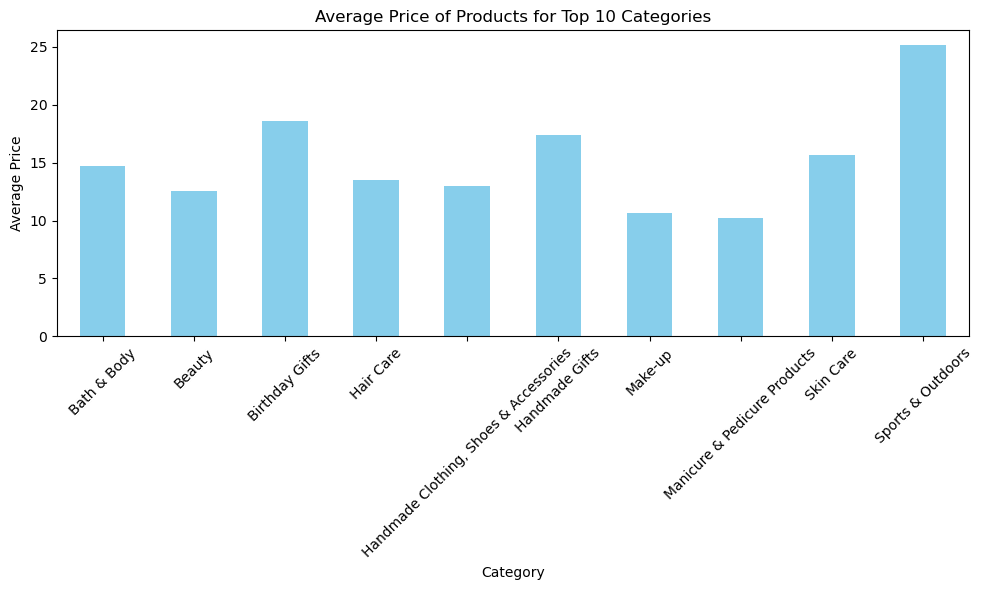

In [28]:
# Step 3: Bar Charts for Average Price
top_10_categories = df_no_outliers['category'].value_counts().nlargest(10).index

avg_price = df_no_outliers[df_no_outliers['category'].isin(top_10_categories)].groupby('category')['price'].mean()

plt.figure(figsize=(10, 6))
avg_price.plot(kind='bar', color='skyblue')
plt.title('Average Price of Products for Top 10 Categories')
plt.xlabel('Category')
plt.ylabel('Average Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

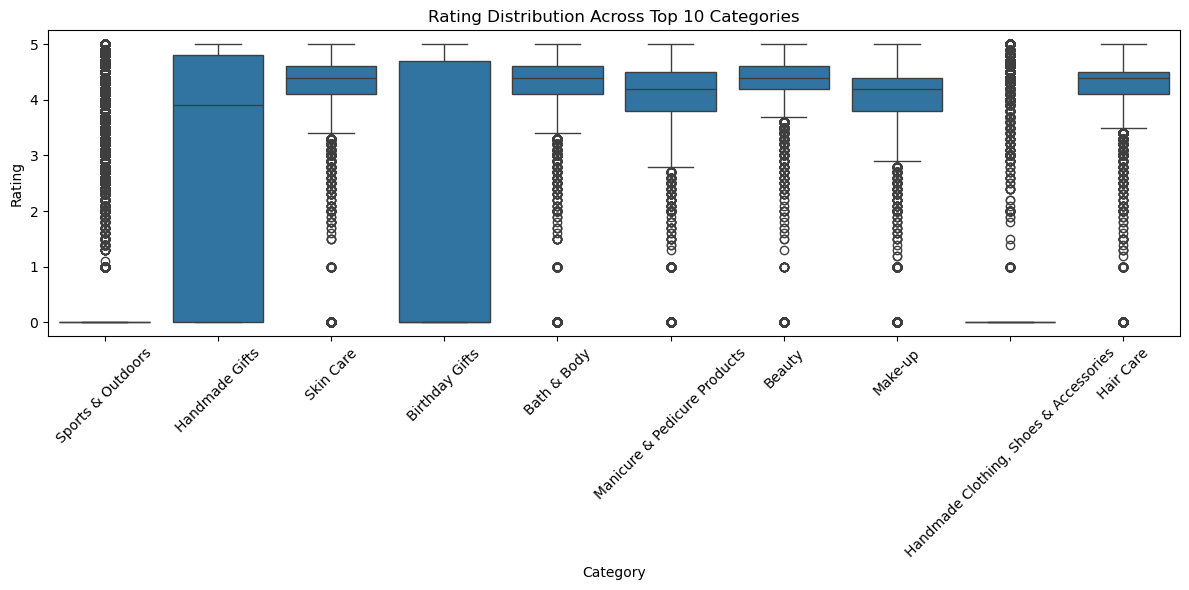

In [29]:
# Step 4: Box Plots for Product Ratings
plt.figure(figsize=(12, 6))
sns.boxplot(x='category', y='stars', data=df_no_outliers[df_no_outliers['category'].isin(top_10_categories)])
plt.title('Rating Distribution Across Top 10 Categories')
plt.xticks(rotation=45)
plt.ylabel('Rating')
plt.xlabel('Category')
plt.tight_layout()
plt.show()

In [ ]:
#Interpretation: After running the code, you can identify which product categories have the highest median prices and average prices, 
#as well as which categories receive the highest ratings.


Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?
Visualizations:

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.

In [38]:
# Step 1: Calculate Correlation Coefficient
correlation_coefficient = df['price'].corr(df['stars'])
print(f"Correlation Coefficient between Price and Stars: {correlation_coefficient:.2f}")


Correlation Coefficient between Price and Stars: -0.12


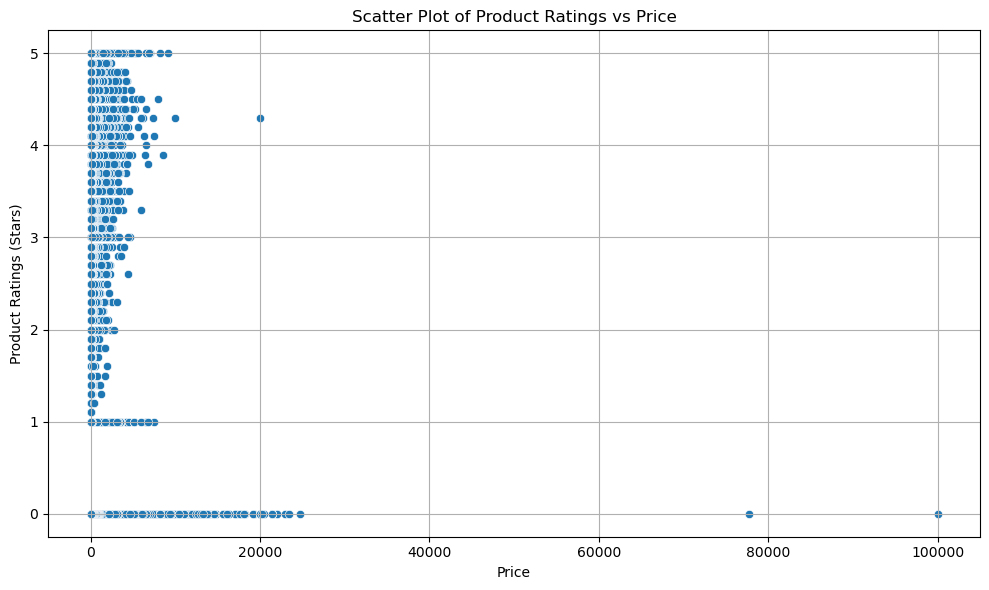

In [40]:
# Step 2: Scatter Plot Visualization
plt.figure(figsize=(10, 6))
sns.scatterplot(x='price', y='stars', data=df)
plt.title('Scatter Plot of Product Ratings vs Price')
plt.xlabel('Price')
plt.ylabel('Product Ratings (Stars)')
plt.grid()
plt.tight_layout()
plt.show()

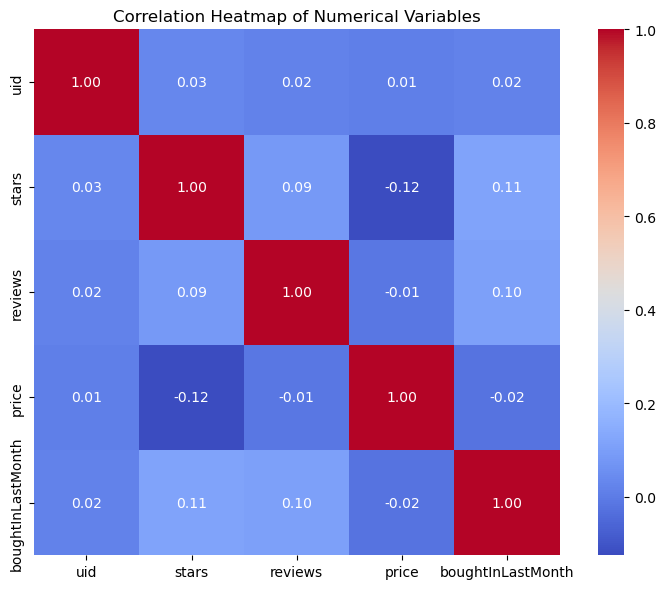

In [41]:
# Step 3: Correlation Heatmap
# Select only numeric columns
numeric_df = df.select_dtypes(include=[np.number])

# Create the correlation matrix
correlation_matrix = numeric_df.corr()

# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", square=True)
plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()

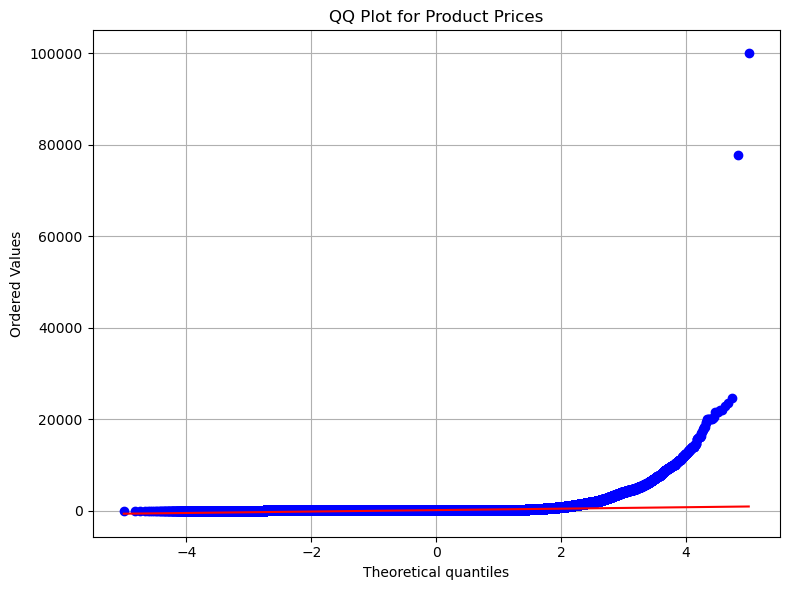

In [42]:
# Step 4: QQ Plot for Price Distribution
plt.figure(figsize=(8, 6))
stats.probplot(df['price'], dist="norm", plot=plt)
plt.title('QQ Plot for Product Prices')
plt.grid()
plt.tight_layout()
plt.show()